## 0. Setup & load

In [ ]:
import sys
import subprocess
import json
import math
from pathlib import Path
from datetime import timedelta

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import optuna
import lightgbm as lgb
from feature_engine.creation import CyclicalFeatures, GeoDistanceFeatures
from feature_engine.datetime import DatetimeFeatures
from feature_engine.pipeline import Pipeline
from feature_engine.imputation import MeanMedianImputer
from feature_engine.encoding import OrdinalEncoder

from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
import joblib
from PIL import Image
plt.style.use('ggplot')

/home/abisoye-ubuntu/miniconda3/envs/spotter/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATA = Path('data')
train = pd.read_csv(DATA / 'train-test.csv', parse_dates=['date'])
test = pd.read_csv(DATA / 'validation.csv', parse_dates=['date'])
test_template = pd.read_csv(DATA / 'validation-predictions-template.csv')
dec = pd.read_csv(DATA / 'december-chart-inputs.csv', parse_dates=['date'])
ROOT = Path('..')

In [3]:
def plot_numeric_over_time(df, date_col="date", cols=None, freq="W", ncols=3):
    d = df.set_index(pd.to_datetime(df[date_col])).sort_index()
    cols = cols or d.select_dtypes("number").columns.tolist()
    d = d[cols].resample(freq).mean()
    nrows = math.ceil(len(cols) / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3 * nrows), sharex=False, squeeze=False)
    for ax, c in zip(axes.flat, cols):
        d[c].plot(ax=ax, title=c)
    for ax in axes.flat[len(cols):]:
        ax.set_visible(False)

    fig.tight_layout()
    plt.show()


def plot_regression(y_true, y_pred, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].scatter(y_true, y_pred, s=4, alpha=0.25, color="#064A56")
    lim = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
    axes[0].plot(lim, lim, "r--", lw=1)
    axes[0].set_xlabel("Actual")
    axes[0].set_ylabel("Predicted")
    axes[0].set_title(title)
    axes[1].hist(y_true - y_pred, bins=50, color="#0A5F6E", alpha=0.85)
    axes[1].set_title("Residuals")
    fig.tight_layout()
    plt.show()

## 1. EDA

### Shapes & previews

In [4]:
print(train.shape, test.shape, dec.shape)

(48000, 14) (12000, 13) (31, 7)


In [5]:
train.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [6]:
test.head()

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal
0,TE-000001,Baton Rouge,Mobile,30.50134,-92.65374,31.80442,-88.25195,331.4,Flatbed,19958.0,2025-11-01,0.90402,1.86388
1,TE-000002,Savannah,Los Angeles,33.60973,-82.29994,28.56624,-116.70249,2406.2,Reefer,34114.0,2025-11-01,0.92851,1.86240
2,TE-000003,San Francisco,Raleigh,35.19670,-121.69849,35.37376,-77.47605,2846.6,Dry Van,33435.0,2025-11-01,0.88117,1.95480
3,TE-000004,Dayton,Los Angeles,39.87206,-85.62931,28.56624,-116.70249,2261.6,Dry Van,25392.0,2025-11-01,0.89156,2.14579
4,TE-000005,Memphis,San Antonio,35.56802,-89.52871,29.50969,-98.40059,800.4,Flatbed,NaN,2025-11-01,0.88308,2.22541


In [7]:
dec.head()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,NaN
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,NaN


In [8]:
dec.tail()

,pickup,delivery,distance,equipment,weight,date,predicted_rate
26,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-27,NaN
27,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-28,NaN
28,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-29,NaN
29,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-30,NaN
30,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-31,NaN


### Dtypes, nulls, cardinality

In [9]:
train.dtypes

load_id                 object
pickup                  object
delivery                object
pickup_lat             float64
pickup_lon             float64
delivery_lat           float64
delivery_lon           float64
distance               float64
equipment               object
weight                 float64
date            datetime64[ns]
market_index           float64
quote_signal           float64
posted_rate            float64
dtype: object

In [10]:
test.dtypes

load_id                 object
pickup                  object
delivery                object
pickup_lat             float64
pickup_lon             float64
delivery_lat           float64
delivery_lon           float64
distance               float64
equipment               object
weight                 float64
date            datetime64[ns]
market_index           float64
quote_signal           float64
dtype: object

In [11]:
print(train.isnull().sum())

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64


In [12]:
print(test.isnull().sum())

load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          165
date              0
market_index    249
quote_signal      0
dtype: int64


In [13]:
print(train.nunique())

load_id         48000
pickup             64
delivery           64
pickup_lat         64
pickup_lon         63
delivery_lat       64
delivery_lon       63
distance        21204
equipment           3
weight          23678
date              304
market_index    32884
quote_signal    37633
posted_rate     45398
dtype: int64


In [14]:
print(test.nunique())

load_id         12000
pickup             72
delivery           72
pickup_lat         72
pickup_lon         71
delivery_lat       72
delivery_lon       71
distance         9309
equipment           3
weight           9472
date               61
market_index     9520
quote_signal    11117
dtype: int64


In [15]:
train.equipment.unique()

array(['Dry Van', 'Reefer', 'Flatbed'], dtype=object)

### Distributions

In [16]:
train.describe() #-ve weights in train and test

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal,posted_rate
count,48000.000000,48000.000000,48000.000000,48000.000000,48000.000000,47700.000000,48000,47626.000000,48000.000000,48000.000000
mean,35.647545,-90.928964,35.641175,-90.857310,1135.856654,31028.844004,2025-05-31 19:53:29.400000,1.083387,2.062468,2373.980682
min,28.357650,-121.698490,28.357650,-121.698490,70.000000,-47500.000000,2025-01-01 00:00:00,0.676390,0.692280,57.220000
25%,31.986910,-98.400590,31.986910,-98.400590,550.400000,25800.000000,2025-03-18 00:00:00,0.949670,1.891030,1251.555000
50%,35.294790,-88.089150,35.294790,-87.528710,953.300000,31436.500000,2025-05-31 00:00:00,1.055800,2.055750,2030.760000
75%,39.411040,-83.285060,39.411040,-83.285060,1645.525000,37018.000000,2025-08-15 00:00:00,1.219590,2.221685,3330.750000
max,44.302960,-69.500000,44.302960,-69.500000,3439.800000,47500.000000,2025-10-31 00:00:00,1.467780,3.610350,25533.000000
std,4.315285,13.482431,4.317199,13.476589,728.564416,9391.440620,NaN,0.168091,0.291391,1486.493245


In [17]:
test.describe()

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,date,market_index,quote_signal
count,12000.000000,12000.000000,12000.000000,12000.000000,12000.000000,11835.000000,12000,11751.000000,12000.000000
mean,35.574216,-90.724880,35.609538,-90.913530,1141.773100,30506.636248,2025-12-01 02:30:28.800000256,0.926913,2.051334
min,25.500000,-121.698490,25.500000,-121.698490,70.000000,-47500.000000,2025-11-01 00:00:00,0.723610,1.234760
25%,31.986910,-97.226810,32.009290,-98.400590,556.100000,25493.000000,2025-11-16 00:00:00,0.863880,1.903467
50%,35.294790,-87.528710,35.294790,-87.528710,953.600000,31193.000000,2025-12-01 00:00:00,0.922900,2.051230
75%,39.411040,-82.783790,39.411040,-82.783790,1670.500000,36843.500000,2025-12-16 00:00:00,0.992355,2.200030
max,44.302960,-69.500000,44.302960,-69.500000,3325.700000,47500.000000,2025-12-31 00:00:00,1.098950,2.896350
std,4.366999,13.411638,4.351844,13.624744,732.333797,10572.590450,NaN,0.074109,0.219804


In [18]:
train[train.weight < 0].weight.describe()

count      292.000000
mean    -31724.195205
std       8262.536326
min     -47500.000000
25%     -37284.250000
50%     -31821.500000
75%     -25928.500000
max      -5000.000000
Name: weight, dtype: float64

In [19]:
train[train.weight > 0].weight.describe()

count    47408.000000
mean     31415.358674
std       7994.902979
min       5000.000000
25%      25922.000000
50%      31493.500000
75%      37063.000000
max      47500.000000
Name: weight, dtype: float64

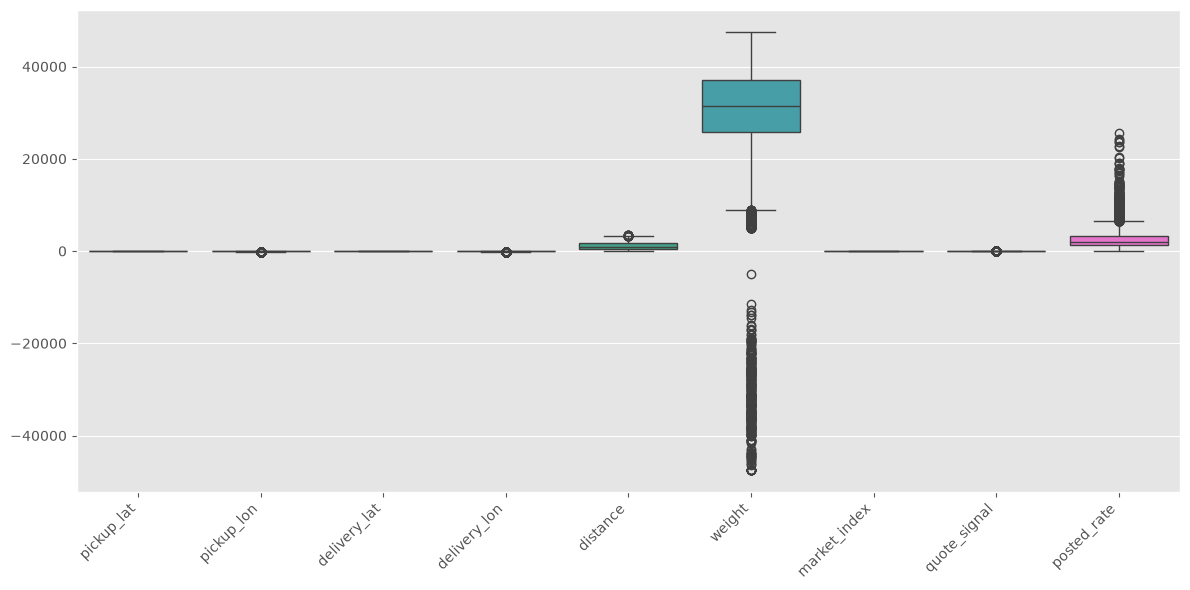

In [20]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=train)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show() #should multiply weight by -1

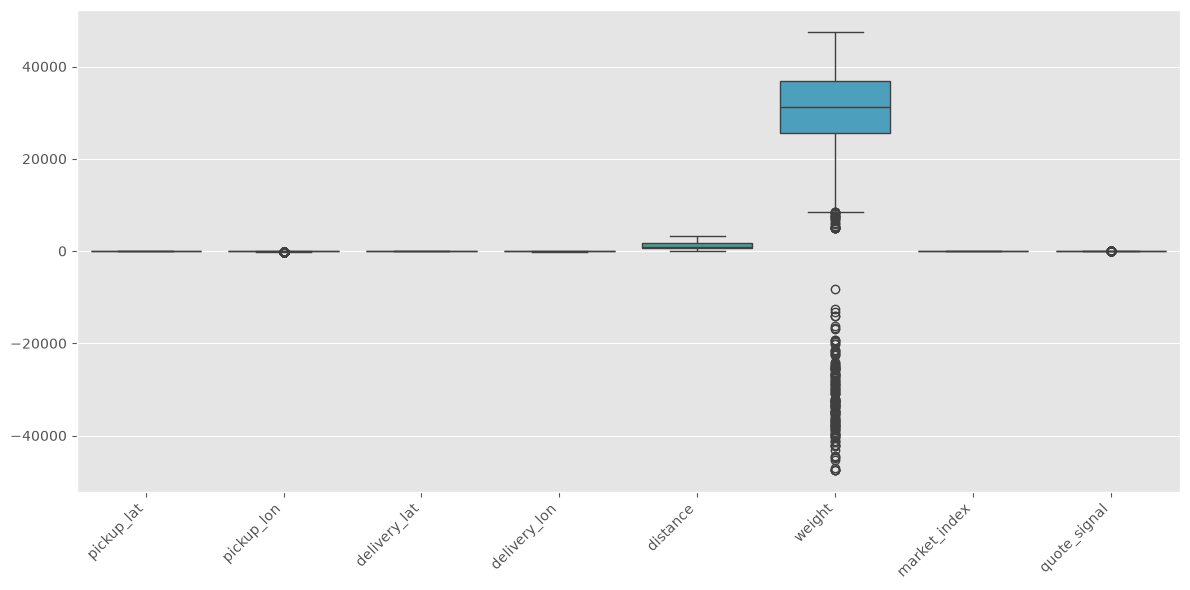

In [21]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=test)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()

### Target

In [22]:
print(train['posted_rate'].skew(), 'log1p skew', np.log1p(train['posted_rate']).skew()) #log transform target

1.9023948792201801 log1p skew -0.4888805885015357


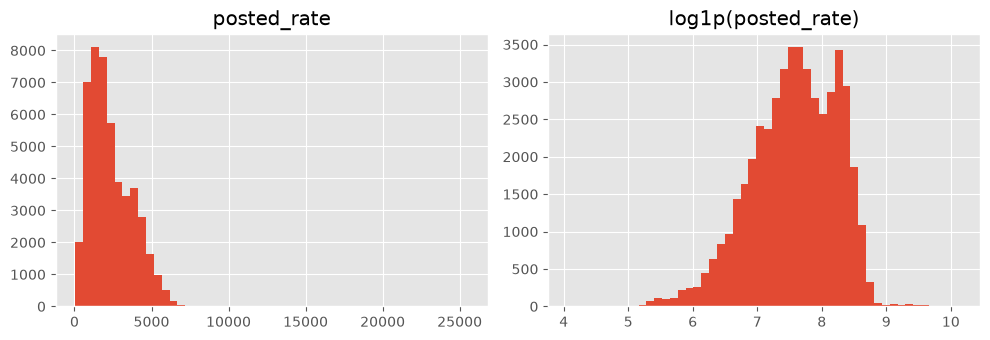

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].hist(train['posted_rate'], bins=50,)
axes[0].set_title('posted_rate')
axes[1].hist(np.log1p(train['posted_rate']), bins=50)
axes[1].set_title('log1p(posted_rate)')
plt.tight_layout()
plt.show()

### Correlations

In [24]:
num = train.select_dtypes(include=[np.number])

In [25]:
corr = num.corr()

In [26]:
corr

,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,weight,market_index,quote_signal,posted_rate
pickup_lat,1.000000,0.559208,-0.008283,-0.006143,-0.077742,0.001898,-0.001735,-0.004181,-0.090873
pickup_lon,0.559208,1.000000,-0.008609,-0.012231,-0.273411,0.006603,0.001432,0.013659,-0.255058
delivery_lat,-0.008283,-0.008609,1.000000,0.557083,-0.080646,-0.004243,-0.002587,-0.002708,-0.091970
delivery_lon,-0.006143,-0.012231,0.557083,1.000000,-0.275657,-0.001144,-0.008487,0.011437,-0.257086
distance,-0.077742,-0.273411,-0.080646,-0.275657,1.000000,0.002544,-0.002181,-0.057244,0.908519
weight,0.001898,0.006603,-0.004243,-0.001144,0.002544,1.000000,-0.001331,0.008159,0.034840
market_index,-0.001735,0.001432,-0.002587,-0.008487,-0.002181,-0.001331,1.000000,-0.067827,0.034165
quote_signal,-0.004181,0.013659,-0.002708,0.011437,-0.057244,0.008159,-0.067827,1.000000,-0.039858
posted_rate,-0.090873,-0.255058,-0.091970,-0.257086,0.908519,0.034840,0.034165,-0.039858,1.000000


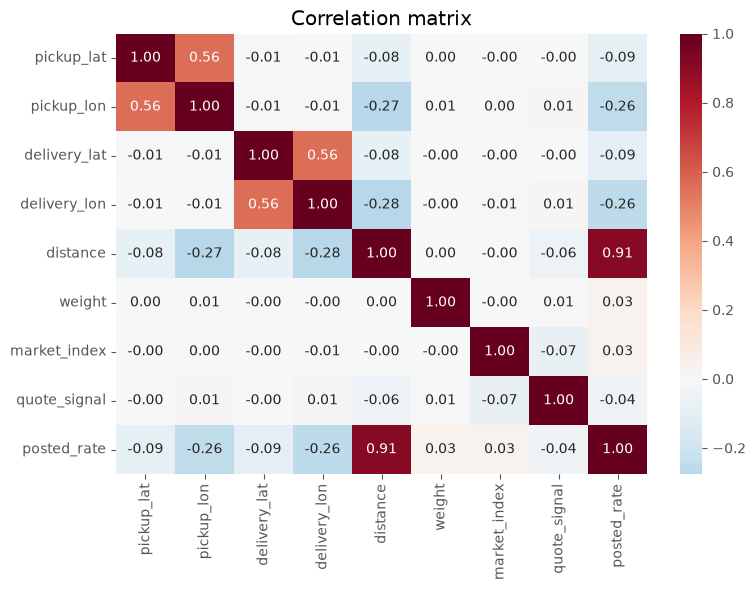

In [27]:
plt.figure(figsize=(8, 6))
sns.heatmap(corr, cmap='RdBu_r', center=0, annot=True, fmt='.2f')
plt.title('Correlation matrix')
plt.tight_layout()
plt.show() #features don't have high amt of correlation between themselves but distance is highly correlated with target

In [28]:
pairs = [(corr.columns[i], corr.columns[j], corr.iloc[i,j])
        for i in range(len(corr.columns)) for j in range(i+1, len(corr.columns))
        if abs(corr.iloc[i,j]) >= 0.85]
print('high corr pairs', pairs)

high corr pairs [('distance', 'posted_rate', np.float64(0.9085191518300795))]


### Over time

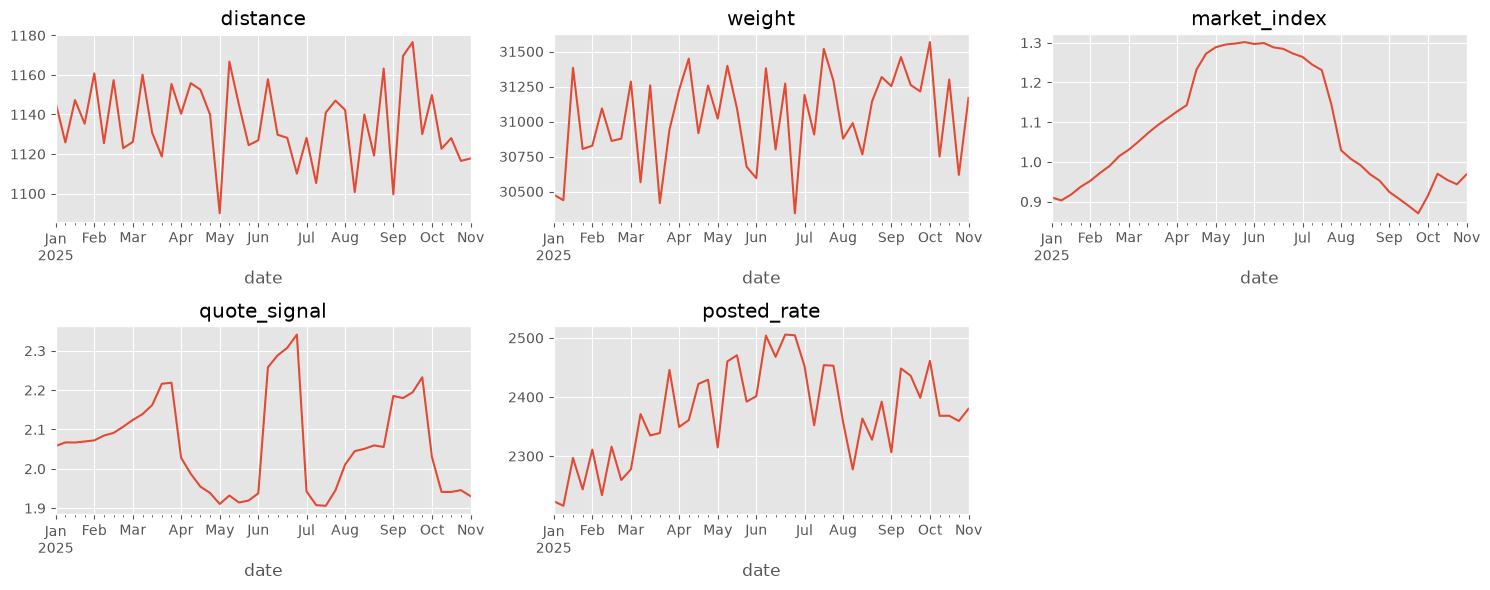

In [29]:
plot_numeric_over_time(train, cols = ['distance', 'weight', 'market_index', 'quote_signal', 'posted_rate'])

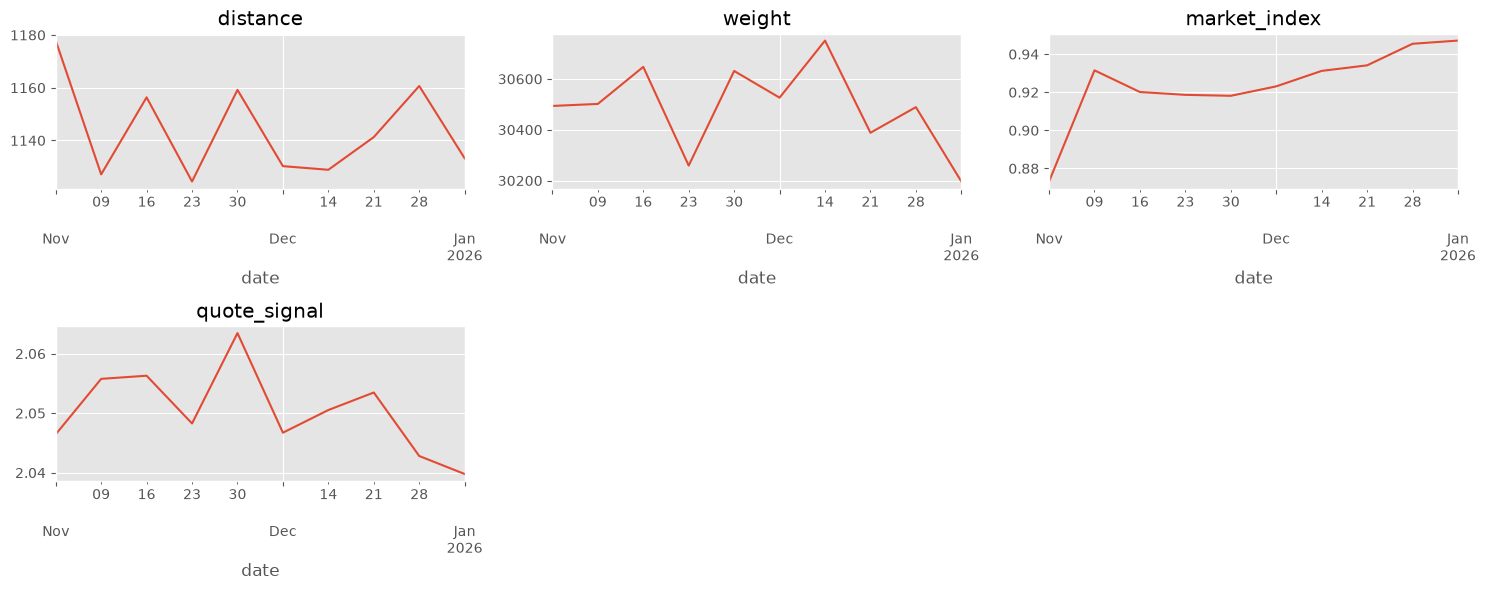

In [30]:
plot_numeric_over_time(test , cols = ['distance', 'weight', 'market_index', 'quote_signal'])

## 2. Feature engineering

### Cleaning and split

In [31]:
train['weight'] = np.where(train.weight < 0, train.weight * -1, train.weight)
test['weight'] = np.where(test.weight < 0, test.weight * -1, test.weight)

In [32]:
train.weight.describe()

count    47700.000000
mean     31417.249245
std       7996.515399
min       5000.000000
25%      25922.000000
50%      31496.000000
75%      37063.250000
max      47500.000000
Name: weight, dtype: float64

In [33]:
X, y = train.drop(columns = ['posted_rate']), train[['date', 'posted_rate']]

In [34]:
#split data
cutoff = X.date.max() - timedelta(days=31)
print(X.date.max(), cutoff)

Xtrain = X.query('date <= @cutoff').copy()
Xval = X.query('date > @cutoff').copy()

ytrain = y.query('date <= @cutoff')
yval = y.query('date > @cutoff')

2025-10-31 00:00:00 2025-09-30 00:00:00


### Weight imputation (train medians only)

In [35]:
equip_median_wt = Xtrain.groupby('equipment')['weight'].median().to_dict()
equip_median_wt

{'Dry Van': 31438.0, 'Flatbed': 31538.0, 'Reefer': 31586.0}

In [36]:
Xtrain["weight"] = Xtrain["weight"].fillna(Xtrain["equipment"].map(equip_median_wt))
Xval["weight"] = Xval["weight"].fillna(Xval["equipment"].map(equip_median_wt))
test["weight"] = test["weight"].fillna(test["equipment"].map(equip_median_wt))

### Feature pipeline (fit on train split only)

In [37]:
def add_features(df):
    out = df.copy()
    d = out["distance"]

    out["weight"] = out["weight"].abs()

    out["log_distance"] = np.log1p(d)
    out["sqrt_distance"] = np.sqrt(d)
    out["distance_sq"] = d ** 2
    out["distance_cbrt"] = np.cbrt(d)
    out["inv_distance"] = 1.0 / d
    out["distance_bin"] = pd.cut(d, [0, 250, 500, 1000, 1500, 3000, 1e6], labels=False).astype(float)

    out["dist_vs_haversine"] = d / out["haversine_miles"].clip(lower=1)
    out["bearing"] = np.arctan2(
        out["delivery_lon"] - out["pickup_lon"],
        out["delivery_lat"] - out["pickup_lat"],
    )
    return out


feature_pipe = Pipeline([
    ("datetime", DatetimeFeatures(
        variables="date",
        features_to_extract=["month", "day_of_week", "day_of_year"],
    )),
    ("cyclical", CyclicalFeatures(
        variables=["date_month", "date_day_of_week", "date_day_of_year"],
        max_values={"date_month": 12, "date_day_of_week": 6, "date_day_of_year": 365},
        drop_original=False,
    )),
    ("market_index", MeanMedianImputer(imputation_method="median", variables=["market_index"])),
    ("equipment", OrdinalEncoder(encoding_method="arbitrary", variables=["equipment"])),
    ("haversine", GeoDistanceFeatures(
        lat1="pickup_lat", lon1="pickup_lon",
        lat2="delivery_lat", lon2="delivery_lon",
        method="haversine", output_unit="miles",
        output_col="haversine_miles", drop_original=False, validate_ranges=False,
    )),
    ("features", FunctionTransformer(add_features)),
])

In [38]:
Xtrain_fe = feature_pipe.fit_transform(Xtrain)
Xval_fe = feature_pipe.transform(Xval)
test_fe = feature_pipe.transform(test)

In [39]:
Xtrain_fe.isna().sum()

load_id                 0
pickup                  0
delivery                0
pickup_lat              0
pickup_lon              0
delivery_lat            0
delivery_lon            0
distance                0
equipment               0
weight                  0
market_index            0
quote_signal            0
date_month              0
date_day_of_week        0
date_day_of_year        0
date_month_sin          0
date_month_cos          0
date_day_of_week_sin    0
date_day_of_week_cos    0
date_day_of_year_sin    0
date_day_of_year_cos    0
haversine_miles         0
log_distance            0
sqrt_distance           0
distance_sq             0
distance_cbrt           0
inv_distance            0
distance_bin            0
dist_vs_haversine       0
bearing                 0
dtype: int64

In [40]:
ytrain.isna().sum()

date           0
posted_rate    0
dtype: int64

In [41]:
Xval_fe.isna().sum()

load_id                 0
pickup                  0
delivery                0
pickup_lat              0
pickup_lon              0
delivery_lat            0
delivery_lon            0
distance                0
equipment               0
weight                  0
market_index            0
quote_signal            0
date_month              0
date_day_of_week        0
date_day_of_year        0
date_month_sin          0
date_month_cos          0
date_day_of_week_sin    0
date_day_of_week_cos    0
date_day_of_year_sin    0
date_day_of_year_cos    0
haversine_miles         0
log_distance            0
sqrt_distance           0
distance_sq             0
distance_cbrt           0
inv_distance            0
distance_bin            0
dist_vs_haversine       0
bearing                 0
dtype: int64

In [42]:
test_fe.isna().sum()

load_id                 0
pickup                  0
delivery                0
pickup_lat              0
pickup_lon              0
delivery_lat            0
delivery_lon            0
distance                0
equipment               0
weight                  0
market_index            0
quote_signal            0
date_month              0
date_day_of_week        0
date_day_of_year        0
date_month_sin          0
date_month_cos          0
date_day_of_week_sin    0
date_day_of_week_cos    0
date_day_of_year_sin    0
date_day_of_year_cos    0
haversine_miles         0
log_distance            0
sqrt_distance           0
distance_sq             0
distance_cbrt           0
inv_distance            0
distance_bin            0
dist_vs_haversine       0
bearing                 0
dtype: int64

## 3. Models

### Statistical baselines

/tmp/ipykernel_105409/2955547275.py:7: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  recent = ytrain.loc[Xtrain["date"] > cutoff - pd.Timedelta(days=30), "posted_rate"].mean()


global_median   RMSE=1567.97  R2=-0.052


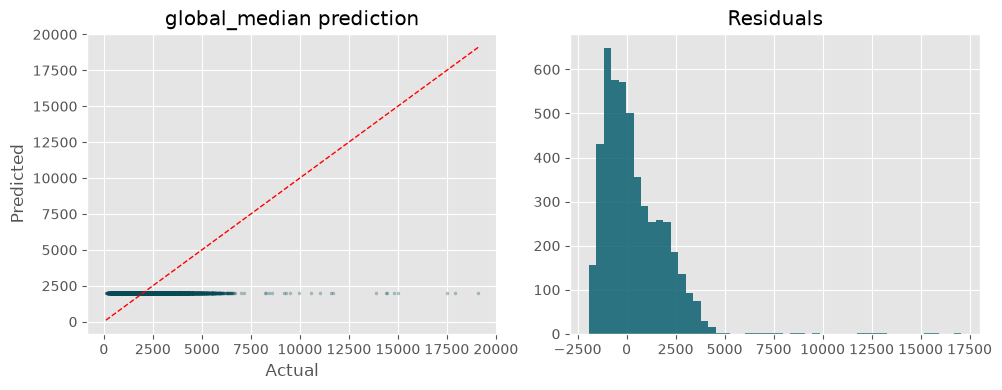

equip_median    RMSE=1558.82  R2=-0.040


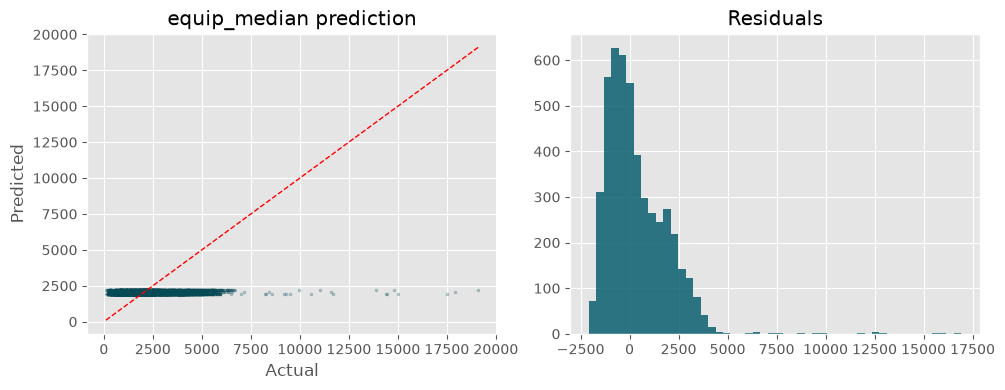

equip_rpm       RMSE=683.87  R2=0.800


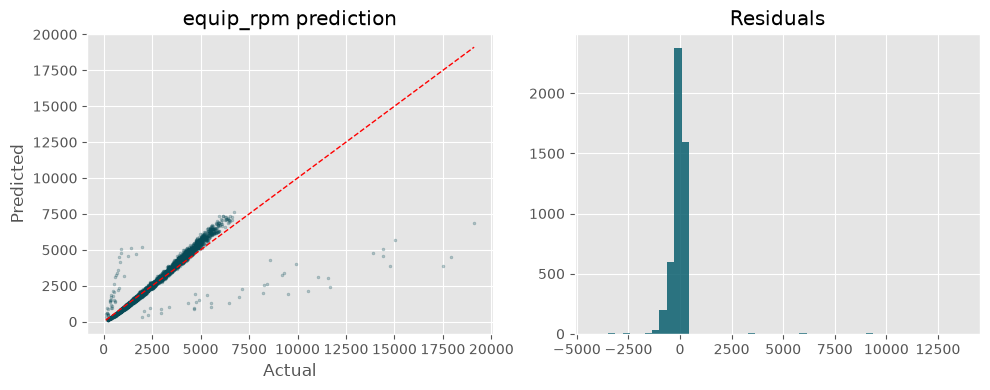

recent_30d      RMSE=1528.80  R2=-0.000


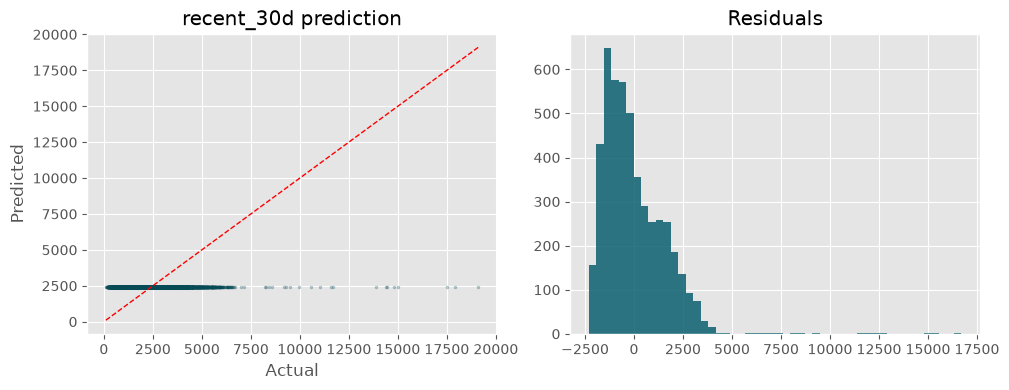

In [43]:
med = ytrain["posted_rate"].median()
rpm = ytrain["posted_rate"] / Xtrain["distance"]
rpm_med = rpm.median()

equip_median_rate = ytrain["posted_rate"].groupby(Xtrain["equipment"]).median().to_dict()
equip_median_rpm = rpm.groupby(Xtrain["equipment"]).median().to_dict()
recent = ytrain.loc[Xtrain["date"] > cutoff - pd.Timedelta(days=30), "posted_rate"].mean()

preds = {
    "global_median": np.full(len(Xval), med),
    "equip_median": Xval["equipment"].map(equip_median_rate).fillna(med),
    "equip_rpm": Xval["equipment"].map(equip_median_rpm).fillna(rpm_med) * Xval["distance"],
    "recent_30d": np.full(len(Xval), recent),
}

for name, pred in preds.items():
    print(f"{name:15s} RMSE={root_mean_squared_error(yval['posted_rate'], pred):.2f}  R2={r2_score(yval['posted_rate'], pred):.3f}")
    plot_regression(yval['posted_rate'], pred, title=f"{name} prediction")

### Model baselines

linear_reg      RMSE=654.3379  R2=0.8168


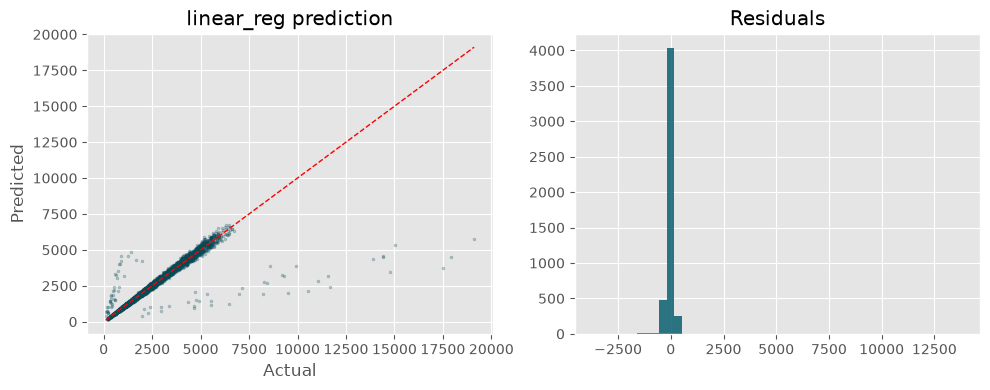

xgboost         RMSE=717.8681  R2=0.7794


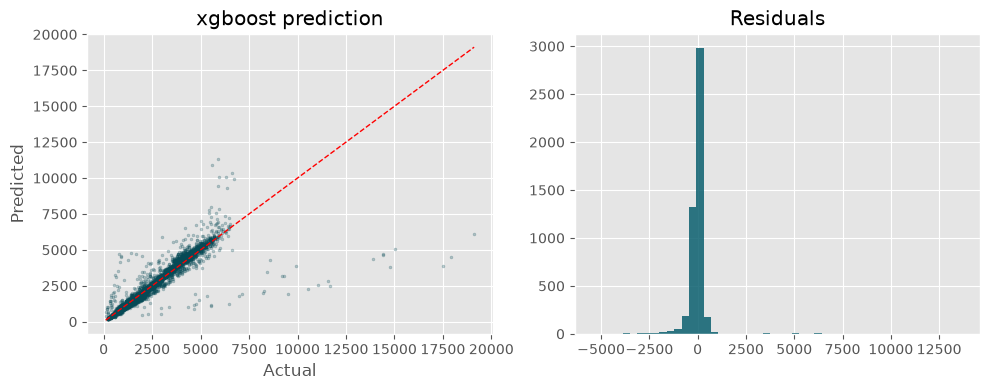

lightgbm        RMSE=651.1694  R2=0.8185


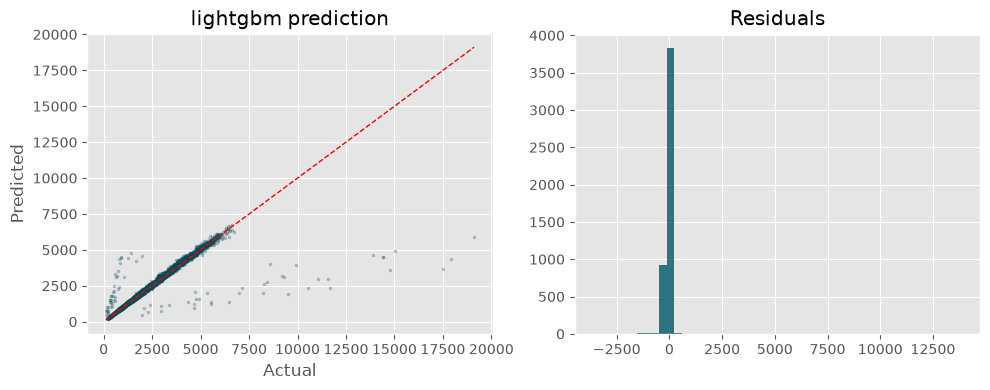

catboost        RMSE=655.0374  R2=0.8164


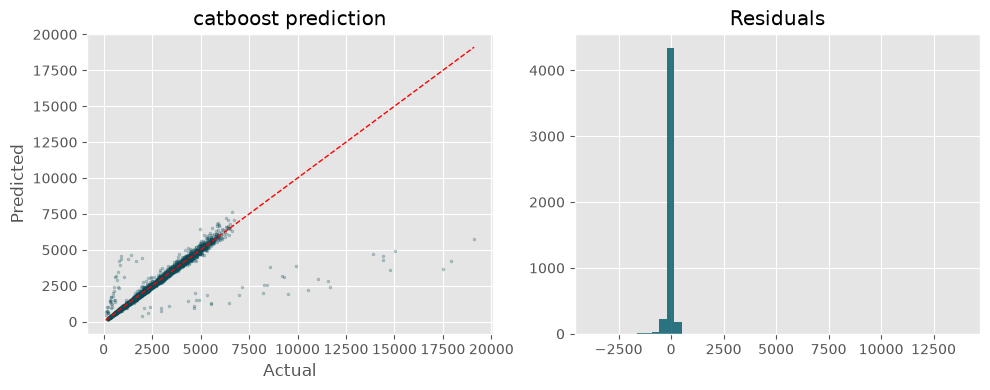

In [44]:
drop = ["load_id", "pickup", "delivery", "date"]
Xtr = Xtrain_fe.drop(columns=drop, errors="ignore")
Xva = Xval_fe.drop(columns=drop, errors="ignore")
ytr, yva = ytrain["posted_rate"], yval["posted_rate"]


def logy(model):
    return TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)


models = {
    "linear_reg": logy(make_pipeline(StandardScaler(), LinearRegression())),
    "xgboost": logy(XGBRegressor(random_state=42)),
    "lightgbm": logy(LGBMRegressor(random_state=42, verbose=-1)),
    "catboost": logy(CatBoostRegressor(random_state=42, verbose=0)),
}

for name, model in models.items():
    model.fit(Xtr, ytr)
    pred = model.predict(Xva)
    print(f"{name:15s} RMSE={root_mean_squared_error(yva, pred):.4f}  R2={r2_score(yva, pred):.4f}")
    plot_regression(yva, pred, title=f"{name} prediction")

### Hyperparameter tuning (Optuna)

In [45]:
SEED = 42
N_TRIALS =  5

In [46]:
order = Xtrain["date"].sort_values().index
Xs, ys = Xtr.loc[order], ytr.loc[order]
tscv = TimeSeriesSplit(n_splits=5, test_size=31)

In [47]:
def suggest_lgbm(trial):
    return {
        "n_estimators": trial.suggest_int("n_estimators", 200, 1500, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "reg_alpha": trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10, log=True),
        "num_leaves": trial.suggest_int("num_leaves", 15, 255),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
    }


In [48]:
def build_lgbm(params):
    base = LGBMRegressor(
        **params,
        subsample_freq=1,
        random_state=SEED,
        n_jobs=-1,
        verbose=-1,
    )
    return TransformedTargetRegressor(
        regressor=base,
        func=np.log1p,
        inverse_func=np.expm1,
    )


In [49]:
def objective(trial):
    params = suggest_lgbm(trial)
    scores = []

    for i, (train_idx, val_idx) in enumerate(tscv.split(Xs)):
        model = build_lgbm(params).fit(Xs.iloc[train_idx], ys.iloc[train_idx])
        pred = model.predict(Xs.iloc[val_idx])
        score = root_mean_squared_error(ys.iloc[val_idx], pred)
        scores.append(score)

        trial.report(float(np.mean(scores)), i)
        if trial.should_prune():
            raise optuna.TrialPruned()

    return float(np.mean(scores))

In [50]:
study = optuna.create_study(
    direction="minimize",
    sampler=optuna.samplers.TPESampler(seed=SEED),
    pruner=optuna.pruners.MedianPruner(),
)
study.optimize(objective, n_trials=N_TRIALS)

[I 2026-10-23 18:31:28,730] A new study created in memory with name: no-name-9d0bfc03-e7bf-4d28-b91e-eaa200301788
[I 2026-10-23 18:33:11,962] Trial 0 finished with value: 479.07197861703054 and parameters: {'n_estimators': 700, 'learning_rate': 0.17254716573280354, 'subsample': 0.892797576724562, 'max_depth': 7, 'colsample_bytree': 0.5780093202212182, 'reg_alpha': 0.004207053950287938, 'reg_lambda': 0.0017073967431528124, 'num_leaves': 223, 'min_child_samples': 62}. Best is trial 0 with value: 479.07197861703054.
[I 2026-10-23 18:38:43,958] Trial 1 finished with value: 416.9114983265408 and parameters: {'n_estimators': 1100, 'learning_rate': 0.010636066512540286, 'subsample': 0.9879639408647978, 'max_depth': 9, 'colsample_bytree': 0.6061695553391381, 'reg_alpha': 0.005337032762603957, 'reg_lambda': 0.00541524411940254, 'num_leaves': 88, 'min_child_samples': 55}. Best is trial 1 with value: 416.9114983265408.
[I 2026-10-23 18:40:19,618] Trial 2 finished with value: 426.1106741564666 and

In [51]:
best_params = study.best_params
best_value = study.best_value

In [52]:
best_params

{'n_estimators': 600,
 'learning_rate': 0.013399060561509796,
 'subsample': 0.8736932106048627,
 'max_depth': 6,
 'colsample_bytree': 0.5610191174223894,
 'reg_alpha': 0.09565499215943825,
 'reg_lambda': 0.0013726318898045872,
 'num_leaves': 234,
 'min_child_samples': 29}

In [53]:
best_value

415.66177235667936

### Model selection

In [54]:
# final model on full training set
best_model = build_lgbm(best_params)
best_model.fit(Xtr, ytr)
pred = best_model.predict(Xva)

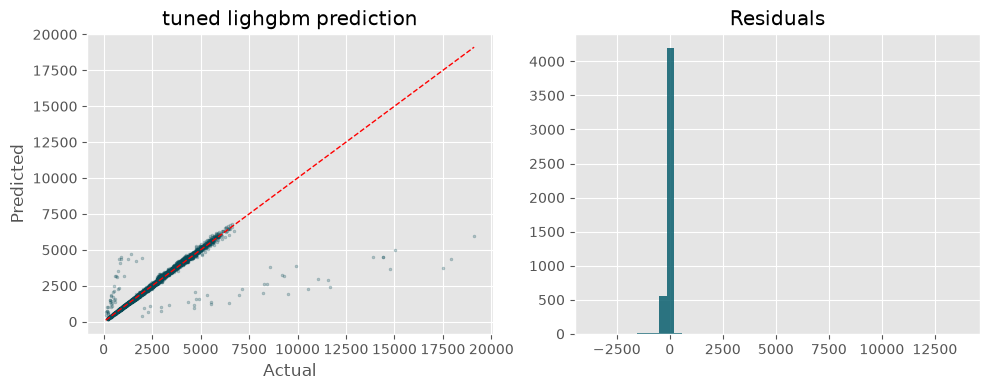

In [55]:
plot_regression(yva, pred, title=f"tuned lighgbm prediction")

In [56]:
holdout_rmse = root_mean_squared_error(yva, pred)
holdout_r2 = r2_score(yva, pred)

print(f"Holdout RMSE   : {holdout_rmse:.4f}")
print(f"Holdout R²     : {holdout_r2:.4f}")
#RMSE=651.17  R2=0.819: lgbm baseline

Holdout RMSE   : 648.6727
Holdout R²     : 0.8199


## 4. Final artifacts

In [57]:
X_full = X.copy()
X_full["weight"] = X_full["weight"].fillna(X_full["equipment"].map(equip_median_wt))
y_full = y["posted_rate"]

feature_pipe.fit(X_full)
Xtr_full = feature_pipe.transform(X_full).drop(columns=drop, errors="ignore")
Xte = feature_pipe.transform(test).drop(columns=drop, errors="ignore")

In [58]:
final_model = build_lgbm(best_params)
final_model.fit(Xtr_full, y_full)

,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.","LGBMRegressor...1, verbose=-1)"
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",<ufunc 'log1p'>
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",<ufunc 'expm1'>
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[<U20](27,)","['pickup_lat','pickup_lon','delivery_lat',...,'distance_bin', 'dist_vs_haversine','bearing']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,27
regressor_ regressor_: objectFitted regressor.,LGBMRegressor,"LGBMRegressor...1, verbose=-1)"
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,FunctionTransformer,FunctionTrans...validate=True)
,num_leaves,234


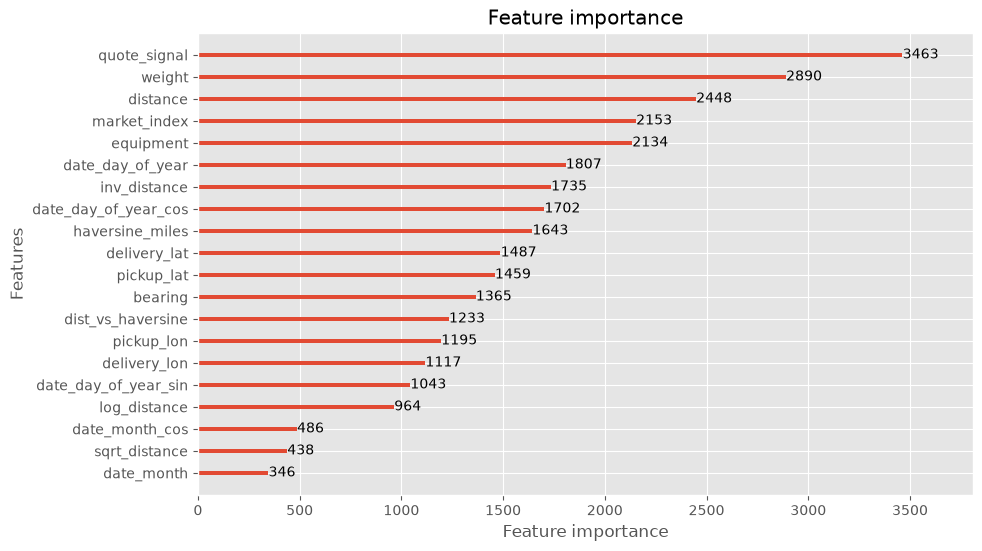

In [59]:
lgb.plot_importance(final_model.regressor_, max_num_features=20, figsize=(10, 6))
plt.show()

In [60]:
OUT = Path("output")
OUT.mkdir(exist_ok=True)

test_template["predicted_rate"] = final_model.predict(Xte)
test_template.to_csv(OUT / "validation_predictions.csv", index=False)

In [63]:
joblib.dump(final_model,     OUT / "final_model.joblib")
joblib.dump(feature_pipe,    OUT / "feature_pipeline.joblib")
joblib.dump(equip_median_wt, OUT / "equip_median_wt.joblib")

['output/equip_median_wt.joblib']

#### 5 December Scoring and Chart

In [64]:
dec = pd.read_csv(DATA / 'december-chart-inputs.csv', parse_dates=['date'])
dec = dec[["pickup", "delivery", "distance", "equipment", "weight", "date"]] 
pu = train[["pickup", "pickup_lat", "pickup_lon"]].drop_duplicates("pickup")
do = train[["delivery", "delivery_lat", "delivery_lon"]].drop_duplicates("delivery")

dec_full = dec.merge(pu, on="pickup", how="left").merge(do, on="delivery", how="left")
dec_full["quote_signal"] = dec_full["date"].map(test.groupby("date")["quote_signal"].median())
dec_full["market_index"] = np.nan
dec_full["load_id"]      = np.nan
dec_full = dec_full[X_full.columns]                                   

Xdec = feature_pipe.transform(dec_full).drop(columns=drop, errors="ignore")

dec_out = dec.copy()
dec_out["predicted_rate"] = final_model.predict(Xdec)
dec_out.to_csv(OUT / "december-chart-inputs.csv", index=False)


In [65]:
!python score.py --predictions output/validation_predictions.csv --december-predictions output/december-chart-inputs.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


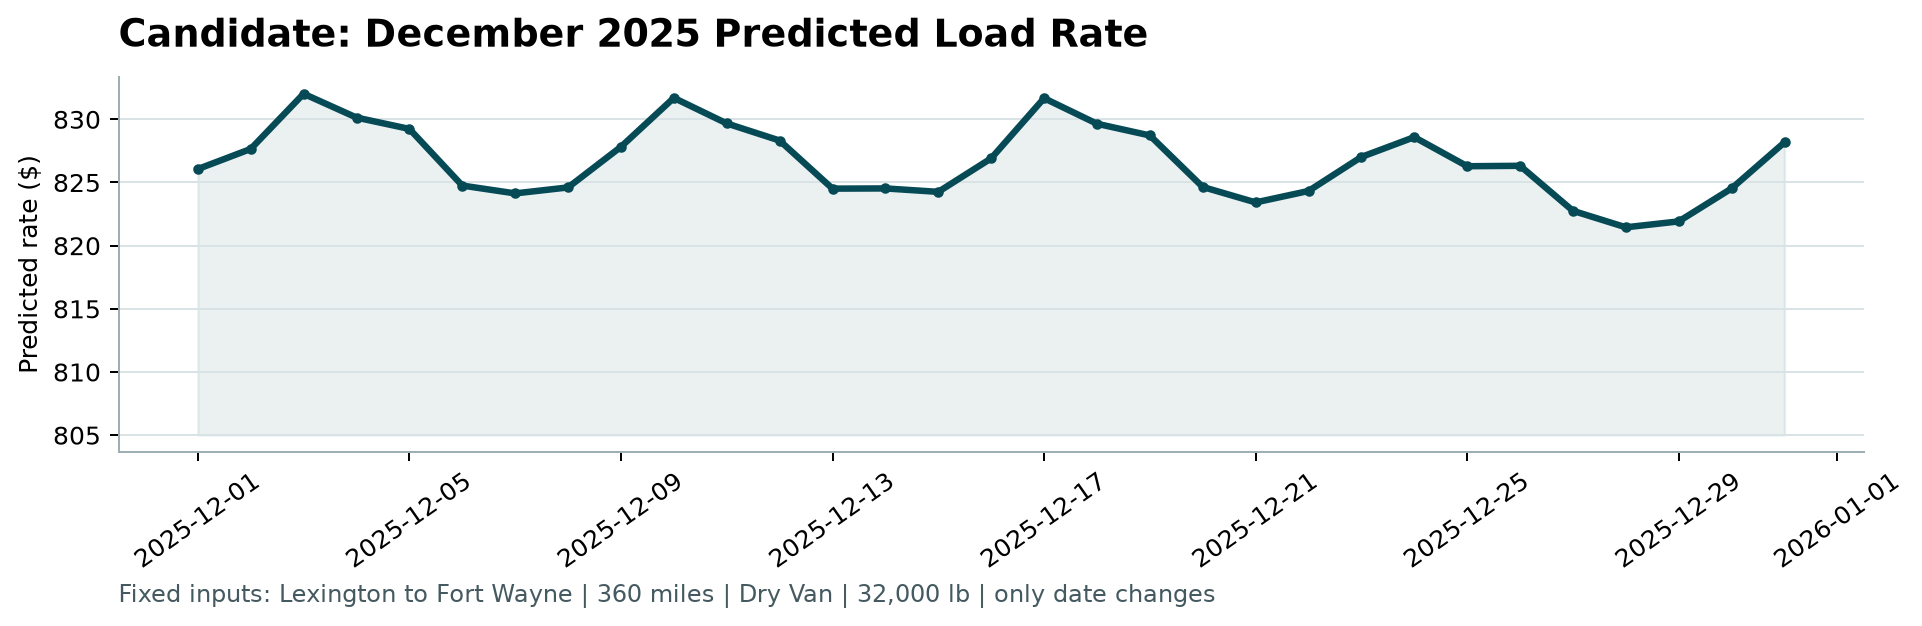

In [ ]:
Image.open('scorer_results/candidate_december.png')